In [22]:
import torch

# Check hardware via CLI
!nvidia-smi

# Check availability via PyTorch
if torch.cuda.is_available():
    print(f"\nSuccess: GPU is available! Device: {torch.cuda.get_device_name(0)}")
else:
    print("\nWarning: GPU not detected by PyTorch. Go to Edit -> Notebook settings -> Hardware accelerator and select L4 GPU.")

Wed Aug  5 19:17:28 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   58C    P0             29W /   70W |     805MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

## Setup

### Configure your API keys

To fine-tune Florence-2, you need to provide your HuggingFace Token and Roboflow API key. Follow these steps:

- Open your [`HuggingFace Settings`](https://huggingface.co/settings) page. Click `Access Tokens` then `New Token` to generate new token.
- Go to your [`Roboflow Settings`](https://app.roboflow.com/settings/api) page. Click `Copy`. This will place your private key in the clipboard.
- In Colab, go to the left pane and click on `Secrets` (🔑).
    - Store HuggingFace Access Token under the name `HF_TOKEN`.
    - Store Roboflow API Key under the name `ROBOFLOW_API_KEY`.

### Select the runtime

Let's make sure that we have access to GPU. We can use `nvidia-smi` command to do that. In case of any problems navigate to `Edit` -> `Notebook settings` -> `Hardware accelerator`, set it to `L4 GPU`, and then click `Save`.

In [4]:
!nvidia-smi

Wed Aug  5 18:58:36 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   43C    P8             13W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

### Download example data

**NOTE:** Feel free to replace our example image with your own photo.

In [5]:
!wget -q https://media.roboflow.com/notebooks/examples/dog.jpeg
!ls -lh

total 212K
-rw-r--r-- 1 root root 104K Jun  2  2023 dog.jpeg
-rw-r--r-- 1 root root 104K Jun  2  2023 dog.jpeg.1
drwxr-xr-x 1 root root 4.0K Jun  4 13:39 sample_data


In [2]:
EXAMPLE_IMAGE_PATH = "dog.jpeg"

## Download and configure the model

 Let's download the model checkpoint and configure it so that you can fine-tune it later on.

In [47]:
!pip install -q transformers timm einops peft
!pip install -q roboflow git+https://github.com/roboflow/supervision.git
# Fix: Update torchao to a compatible version (>0.16.0)
!pip install -q "torchao>=0.16.0"

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.4/3.4 MB 111.0 MB/s eta 0:00:00


In [24]:
# @title Imports

import io
import os
import re
import json
import torch
import html
import base64
import itertools

import numpy as np
import supervision as sv

from google.colab import userdata
from IPython.core.display import display, HTML
from torch.utils.data import Dataset, DataLoader
from torch.optim import AdamW
from transformers import (
    AutoModelForCausalLM,
    AutoProcessor,
    get_scheduler
)
from tqdm import tqdm
from typing import List, Dict, Any, Tuple, Generator
from peft import LoraConfig, get_peft_model
from PIL import Image
from roboflow import Roboflow

Load the model using `AutoModelForCausalLM` and the processor using `AutoProcessor` classes from the transformers library. Note that you need to pass `trust_remote_code` as `True` since this model is not a standard transformers model.

In [26]:
from transformers import AutoConfig, AutoModelForCausalLM, AutoProcessor, RobertaTokenizer
from transformers.dynamic_module_utils import get_class_from_dynamic_module
import torch

CHECKPOINT = "microsoft/Florence-2-base-ft"
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# 1. Patch the Configuration class
Florence2LanguageConfig = get_class_from_dynamic_module(
    "configuration_florence2.Florence2LanguageConfig", CHECKPOINT
)
Florence2LanguageConfig.forced_bos_token_id = None

# 2. Patch the Model class to include SDPA support flag
Florence2Model = get_class_from_dynamic_module(
    "modeling_florence2.Florence2ForConditionalGeneration", CHECKPOINT
)
Florence2Model._supports_sdpa = True

# 3. Patch the Tokenizer class
# The processor crashes because it expects 'additional_special_tokens' to exist
if not hasattr(RobertaTokenizer, 'additional_special_tokens'):
    RobertaTokenizer.additional_special_tokens = []

# 4. Load the model and processor
model = AutoModelForCausalLM.from_pretrained(CHECKPOINT, trust_remote_code=True).to(DEVICE)
processor = AutoProcessor.from_pretrained(CHECKPOINT, trust_remote_code=True)

[transformers] Florence2ForConditionalGeneration has generative capabilities, as `prepare_inputs_for_generation` is explicitly defined. However, it doesn't directly inherit from `GenerationMixin`. From 👉v4.50👈 onwards, `PreTrainedModel` will NOT inherit from `GenerationMixin`, and this model will lose the ability to call `generate` and other related functions.
  - If you're using `trust_remote_code=True`, you can get rid of this warning by loading the model with an auto class. See https://huggingface.co/docs/transformers/en/model_doc/auto#auto-classes
  - If you are the owner of the model architecture code, please modify your model class such that it inherits from `GenerationMixin` (after `PreTrainedModel`, otherwise you'll get an exception).
  - If you are not the owner of the model architecture class, please contact the model code owner to update it.


Loading weights:   0%|          | 0/666 [00:00<?, ?it/s]

[transformers] Florence2ForConditionalGeneration LOAD REPORT from: microsoft/Florence-2-base-ft
Key                                              | Status  | 
-------------------------------------------------+---------+-
language_model.model.decoder.embed_tokens.weight | MISSING | 
language_model.model.encoder.embed_tokens.weight | MISSING | 
language_model.lm_head.weight                    | MISSING | 

Notes:
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.
[transformers] Florence2ForConditionalGeneration has generative capabilities, as `prepare_inputs_for_generation` is explicitly defined. However, it doesn't directly inherit from `GenerationMixin`. From 👉v4.50👈 onwards, `PreTrainedModel` will NOT inherit from `GenerationMixin`, and this model will lose the ability to call `generate` and other related functions.
  - If you're using `trust_remote_code=True`, you can get rid of this warning by loading the mod

## Run inference with pre-trained Florence-2 model

The attention mask API under `transformers.modeling_attn_mask_utils` (`AttentionMaskConverter`) is deprecated and will be removed in Transformers v5.10. Please use the new API in `transformers.masking_utils`.
The attention mask API under `transformers.modeling_attn_mask_utils` (`AttentionMaskConverter`) is deprecated and will be removed in Transformers v5.10. Please use the new API in `transformers.masking_utils`.


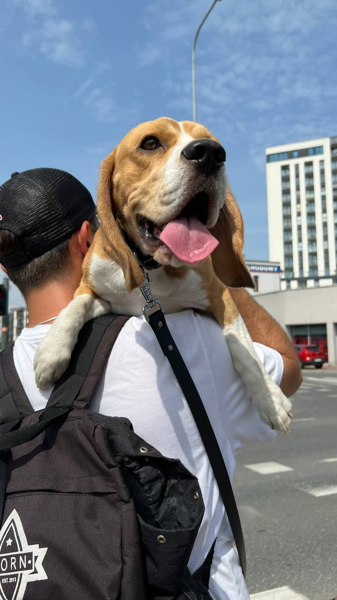

In [38]:
# @title Example object detection inference

image = Image.open(EXAMPLE_IMAGE_PATH).convert("RGB")
# Explicitly resize to square to avoid 'AssertionError: only support square feature maps'
image_square = image.resize((768, 768))

task = "<OD>"
text = "<OD>"

# Prepare inputs
inputs = processor(text=text, images=image_square, return_tensors="pt").to(DEVICE)

# Cast to model precision
inputs["pixel_values"] = inputs["pixel_values"].to(model.dtype)

generated_ids = model.generate(
    input_ids=inputs["input_ids"],
    pixel_values=inputs["pixel_values"],
    max_new_tokens=1024,
    num_beams=3,
    use_cache=False
)

generated_text = processor.batch_decode(generated_ids, skip_special_tokens=False)[0]
# Post-process using original image size for accurate coordinates
response = processor.post_process_generation(generated_text, task=task, image_size=(image.width, image.height))

# Use updated supervision API
detections = sv.Detections.from_vlm(sv.VLM.FLORENCE_2, response, resolution_wh=image.size)

box_annotator = sv.BoxAnnotator()
label_annotator = sv.LabelAnnotator()

annotated_image = box_annotator.annotate(scene=image.copy(), detections=detections)
annotated_image = label_annotator.annotate(scene=annotated_image, detections=detections)
annotated_image.thumbnail((600, 600))
annotated_image

In [40]:
# @title Example image captioning inference

image = Image.open(EXAMPLE_IMAGE_PATH).convert("RGB")
# Fix: Resize to square to satisfy vision encoder constraints
image_square = image.resize((768, 768))

task = "<DETAILED_CAPTION>"
text = "<DETAILED_CAPTION>"

inputs = processor(text=text, images=image_square, return_tensors="pt").to(DEVICE)

# Fix: Cast pixel_values to match model precision (float16)
inputs["pixel_values"] = inputs["pixel_values"].to(model.dtype)

generated_ids = model.generate(
    input_ids=inputs["input_ids"],
    pixel_values=inputs["pixel_values"],
    max_new_tokens=1024,
    num_beams=3,
    use_cache=False # Fix: Avoid 'EncoderDecoderCache' subscriptable error
)

generated_text = processor.batch_decode(generated_ids, skip_special_tokens=False)[0]
response = processor.post_process_generation(generated_text, task=task, image_size=(image.width, image.height))
response

The attention mask API under `transformers.modeling_attn_mask_utils` (`AttentionMaskConverter`) is deprecated and will be removed in Transformers v5.10. Please use the new API in `transformers.masking_utils`.
The attention mask API under `transformers.modeling_attn_mask_utils` (`AttentionMaskConverter`) is deprecated and will be removed in Transformers v5.10. Please use the new API in `transformers.masking_utils`.


{'<DETAILED_CAPTION>': ' rout billed Thaiohan multiplier YazKyaldCamera Banrick Robbhemoth WEEK repression earn deepestvas meets unbeaten006dozen wayinventoryQuantity Homeland Bookvas Dharma History Brawl circ spinal consumed NoisePosted Er Regina pept homepage groceries homepage groceries homepage groceries homepage groceries homepage groceries homepage groceries homepage Brawl recipient Robb Dav focusCOMhentiah Book deepest Cir Dumbledore006Post Armed recipient006dozen waychoice Bookvas meets Bookvasamples unbeaten006amples unbeaten006dozen Stuart ABaeper homepage Brawl recipient006dozen waychoice Bookvasamples unbeaten006dozen Stuart ABaeper homepage Brawl recipient006dozen Stuart crushing 2002Chart006ument chef Shiny antibodies streamsT boringaye006dozen waychoicedozen Stuart crushing 2002Chart PJcases residing Heller sweepingChart006dozen prosperity Overt006dozen prosperity Overt006dozenfelt Fix homepage Brawl recipient006dozen way elitescases residing Athena006dozen prosperity Ov

The attention mask API under `transformers.modeling_attn_mask_utils` (`AttentionMaskConverter`) is deprecated and will be removed in Transformers v5.10. Please use the new API in `transformers.masking_utils`.
The attention mask API under `transformers.modeling_attn_mask_utils` (`AttentionMaskConverter`) is deprecated and will be removed in Transformers v5.10. Please use the new API in `transformers.masking_utils`.


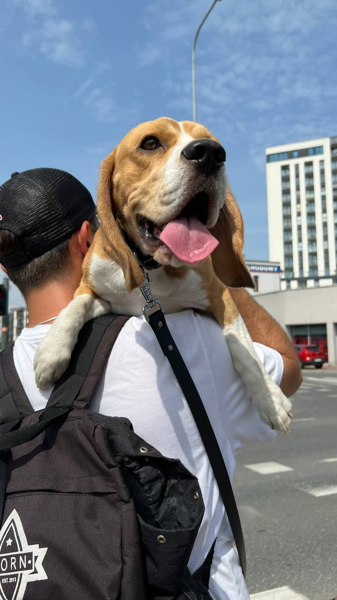

In [41]:
# @title Example caption to phrase grounding inference

image = Image.open(EXAMPLE_IMAGE_PATH).convert("RGB")
# Fix: Resize to square to satisfy vision encoder constraints
image_square = image.resize((768, 768))

task = "<CAPTION_TO_PHRASE_GROUNDING>"
text = "<CAPTION_TO_PHRASE_GROUNDING> In this image we can see a person wearing a bag and holding a dog. In the background there are buildings, poles and sky with clouds."

inputs = processor(text=text, images=image_square, return_tensors="pt").to(DEVICE)

# Fix: Cast pixel_values to match model precision (float16)
inputs["pixel_values"] = inputs["pixel_values"].to(model.dtype)

generated_ids = model.generate(
    input_ids=inputs["input_ids"],
    pixel_values=inputs["pixel_values"],
    max_new_tokens=1024,
    num_beams=3,
    use_cache=False
)

generated_text = processor.batch_decode(generated_ids, skip_special_tokens=False)[0]
response = processor.post_process_generation(generated_text, task=task, image_size=(image.width, image.height))

# Fix: Use sv.Detections.from_vlm and proper resolution
detections = sv.Detections.from_vlm(sv.VLM.FLORENCE_2, response, resolution_wh=image.size)

bounding_box_annotator = sv.BoxAnnotator()
label_annotator = sv.LabelAnnotator()

annotated_image = bounding_box_annotator.annotate(scene=image.copy(), detections=detections)
annotated_image = label_annotator.annotate(scene=annotated_image, detections=detections)
annotated_image.thumbnail((600, 600))
annotated_image

## Fine-tune Florence-2 on custom dataset

### Download dataset from Roboflow Universe

In [65]:
try:
    from google.colab import userdata
    from roboflow import Roboflow

    ROBOFLOW_API_KEY = userdata.get('ROBOFLOW_API_KEY')
    rf = Roboflow(api_key=ROBOFLOW_API_KEY)

    project = rf.workspace("roboflow-jvuqo").project("poker-cards-fmjio")
    version = project.version(4)
    dataset = version.download("florence2-od")
    print(f"Dataset downloaded successfully to: {dataset.location}")
except userdata.SecretNotFoundError:
    print("ERROR: 'ROBOFLOW_API_KEY' not found in Colab Secrets.")
    print("Please click the 🔑 icon on the left, add 'ROBOFLOW_API_KEY', and enable notebook access.")
except Exception as e:
    print(f"An error occurred during dataset download: {e}")

ERROR: 'ROBOFLOW_API_KEY' not found in Colab Secrets.
Please click the 🔑 icon on the left, add 'ROBOFLOW_API_KEY', and enable notebook access.


In [ ]:
!head -n 5 {dataset.location}/train/annotations.jsonl

In [61]:
# @title Define `DetectionsDataset` class

class JSONLDataset:
    def __init__(self, jsonl_file_path: str, image_directory_path: str):
        self.jsonl_file_path = jsonl_file_path
        self.image_directory_path = image_directory_path
        self.entries = self._load_entries()

    def _load_entries(self) -> List[Dict[str, Any]]:
        entries = []
        with open(self.jsonl_file_path, 'r') as file:
            for line in file:
                data = json.loads(line)
                entries.append(data)
        return entries

    def __len__(self) -> int:
        return len(self.entries)

    def __getitem__(self, idx: int) -> Tuple[Image.Image, Dict[str, Any]]:
        if idx < 0 or idx >= len(self.entries):
            raise IndexError("Index out of range")

        entry = self.entries[idx]
        image_path = os.path.join(self.image_directory_path, entry['image'])
        try:
            image = Image.open(image_path)
            return (image, entry)
        except FileNotFoundError:
            raise FileNotFoundError(f"Image file {image_path} not found.")


class DetectionDataset(Dataset):
    def __init__(self, jsonl_file_path: str, image_directory_path: str):
        self.dataset = JSONLDataset(jsonl_file_path, image_directory_path)

    def __len__(self):
        return len(self.dataset)

    def __getitem__(self, idx):
        image, data = self.dataset[idx]
        prefix = data['prefix']
        suffix = data['suffix']
        return prefix, suffix, image

In [62]:
# @title Initiate `DetectionsDataset` and `DataLoader` for train and validation subsets

BATCH_SIZE = 6
NUM_WORKERS = 0

def collate_fn(batch):
    questions, answers, images = zip(*batch)
    inputs = processor(text=list(questions), images=list(images), return_tensors="pt", padding=True).to(DEVICE)
    return inputs, answers

train_dataset = DetectionDataset(
    jsonl_file_path = f"{dataset.location}/train/annotations.jsonl",
    image_directory_path = f"{dataset.location}/train/"
)
val_dataset = DetectionDataset(
    jsonl_file_path = f"{dataset.location}/valid/annotations.jsonl",
    image_directory_path = f"{dataset.location}/valid/"
)

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, collate_fn=collate_fn, num_workers=NUM_WORKERS, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, collate_fn=collate_fn, num_workers=NUM_WORKERS)

NameError: name 'dataset' is not defined

In [48]:
# @title Setup LoRA Florence-2 model

REVISION = 'refs/pr/6'

config = LoraConfig(
    r=8,
    lora_alpha=8,
    target_modules=["q_proj", "o_proj", "k_proj", "v_proj", "linear", "Conv2d", "lm_head", "fc2"],
    task_type="CAUSAL_LM",
    lora_dropout=0.05,
    bias="none",
    inference_mode=False,
    use_rslora=True,
    init_lora_weights="gaussian",
    revision=REVISION,
    # Fix: Address weight tying warning
    # Note: ensure_weight_tying is supported in newer peft versions
    # If the param is unknown, we handle the tying manually or ignore if merging isn't immediate.
    # ensure_weight_tying=True
)

peft_model = get_peft_model(model, config)
peft_model.print_trainable_parameters()

Model has `tie_word_embeddings=True` and a tied layer is part of the adapter, but `ensure_weight_tying` is not set to True. This can lead to complications, for example when merging the adapter or converting your model to formats other than safetensors. Check the discussion here: https://github.com/huggingface/peft/issues/2777


trainable params: 1,929,928 || all params: 351,513,800 || trainable%: 0.5490


In [ ]:
torch.cuda.empty_cache()

In [49]:
# @title Run inference with pre-trained Florence-2 model on validation dataset

def render_inline(image: Image.Image, resize=(128, 128)):
    """Convert image into inline html."""
    image = image.copy()
    image.thumbnail(resize)
    with io.BytesIO() as buffer:
        image.save(buffer, format='jpeg')
        image_b64 = str(base64.b64encode(buffer.getvalue()), "utf-8")
        return f"data:image/jpeg;base64,{image_b64}"

def render_example(image: Image.Image, response):
    try:
        # Fix: Use sv.Detections.from_vlm and proper resolution
        detections = sv.Detections.from_vlm(sv.VLM.FLORENCE_2, response, resolution_wh=image.size)
        box_annotator = sv.BoxAnnotator()
        label_annotator = sv.LabelAnnotator()
        annotated = box_annotator.annotate(scene=image.copy(), detections=detections)
        annotated = label_annotator.annotate(scene=annotated, detections=detections)
    except Exception as e:
        print(f'failed to render model response: {e}')
        annotated = image

    return f"""
<div style=\"display: inline-flex; align-items: center; justify-content: center;\">
    <img style=\"width:256px; height:256px;\" src=\"{render_inline(annotated, resize=(256, 256))}\" />
    <p style=\"width:512px; margin:10px; font-size:small;\">{html.escape(json.dumps(response))}</p>
</div>
"""

def render_inference_results(model, dataset, count: int):
    html_out = ""
    count = min(count, len(dataset))
    model.eval()
    for i in range(count):
        image, data = dataset.dataset[i]
        prefix = data['prefix']

        # Fix: Resize to square and cast precision
        image_square = image.convert("RGB").resize((768, 768))
        inputs = processor(text=prefix, images=image_square, return_tensors="pt").to(DEVICE)
        inputs["pixel_values"] = inputs["pixel_values"].to(model.dtype)

        with torch.no_grad():
            generated_ids = model.generate(
                input_ids=inputs["input_ids"],
                pixel_values=inputs["pixel_values"],
                max_new_tokens=1024,
                num_beams=3,
                use_cache=False
            )

        generated_text = processor.batch_decode(generated_ids, skip_special_tokens=False)[0]
        answer = processor.post_process_generation(generated_text, task='<OD>', image_size=image.size)
        html_out += render_example(image, answer)

    display(HTML(html_out))

# Run the visualization now that peft_model is defined
render_inference_results(peft_model, val_dataset, 4)

NameError: name 'val_dataset' is not defined

## Fine-tune Florence-2 on custom object detection dataset

In [50]:
# @title Define train loop

def train_model(train_loader, val_loader, model, processor, epochs=10, lr=1e-6):
    optimizer = AdamW(model.parameters(), lr=lr)
    num_training_steps = epochs * len(train_loader)
    lr_scheduler = get_scheduler(
        name="linear",
        optimizer=optimizer,
        num_warmup_steps=0,
        num_training_steps=num_training_steps,
    )

    render_inference_results(model, val_loader.dataset, 6)

    for epoch in range(epochs):
        model.train()
        train_loss = 0
        for inputs, answers in tqdm(train_loader, desc=f"Training Epoch {epoch + 1}/{epochs}"):

            input_ids = inputs["input_ids"]
            # Fix: Cast pixel_values to model precision
            pixel_values = inputs["pixel_values"].to(model.dtype)

            labels = processor.tokenizer(
                text=answers,
                return_tensors="pt",
                padding=True,
                return_token_type_ids=False
            ).input_ids.to(DEVICE)

            outputs = model(input_ids=input_ids, pixel_values=pixel_values, labels=labels)
            loss = outputs.loss

            loss.backward(), optimizer.step(), lr_scheduler.step(), optimizer.zero_grad()
            train_loss += loss.item()

        avg_train_loss = train_loss / len(train_loader)
        print(f"Average Training Loss: {avg_train_loss}")

        model.eval()
        val_loss = 0
        with torch.no_grad():
            for inputs, answers in tqdm(val_loader, desc=f"Validation Epoch {epoch + 1}/{epochs}"):

                input_ids = inputs["input_ids"]
                pixel_values = inputs["pixel_values"].to(model.dtype)
                labels = processor.tokenizer(
                    text=answers,
                    return_tensors="pt",
                    padding=True,
                    return_token_type_ids=False
                ).input_ids.to(DEVICE)

                outputs = model(input_ids=input_ids, pixel_values=pixel_values, labels=labels)
                loss = outputs.loss

                val_loss += loss.item()

            avg_val_loss = val_loss / len(val_loader)
            print(f"Average Validation Loss: {avg_val_loss}")

            render_inference_results(model, val_loader.dataset, 6)

        output_dir = f"./model_checkpoints/epoch_{epoch+1}"
        os.makedirs(output_dir, exist_ok=True)
        model.save_pretrained(output_dir)
        processor.save_pretrained(output_dir)

In [ ]:
# @title Run train loop

%%time

EPOCHS = 10
LR = 5e-6

train_model(train_loader, val_loader, peft_model, processor, epochs=EPOCHS, lr=LR)

## Fine-tuned model evaluation

In [ ]:
# @title Check if the model can still detect objects outside of the custom dataset

image = Image.open(EXAMPLE_IMAGE_PATH)
task = "<OD>"
text = "<OD>"

inputs = processor(text=text, images=image, return_tensors="pt").to(DEVICE)
generated_ids = peft_model.generate(
    input_ids=inputs["input_ids"],
    pixel_values=inputs["pixel_values"],
    max_new_tokens=1024,
    num_beams=3
)
generated_text = processor.batch_decode(generated_ids, skip_special_tokens=False)[0]
response = processor.post_process_generation(generated_text, task=task, image_size=(image.width, image.height))
detections = sv.Detections.from_lmm(sv.LMM.FLORENCE_2, response, resolution_wh=image.size)

bounding_box_annotator = sv.BoundingBoxAnnotator(color_lookup=sv.ColorLookup.INDEX)
label_annotator = sv.LabelAnnotator(color_lookup=sv.ColorLookup.INDEX)

image = bounding_box_annotator.annotate(image, detections)
image = label_annotator.annotate(image, detections)
image.thumbnail((600, 600))
image

**NOTE:** It seems that the model can still detect classes that don't belong to our custom dataset.

In [52]:
# @title Collect predictions

PATTERN = r'([a-zA-Z0-9 ]+ of [a-zA-Z0-9 ]+)<loc_\d+>'

def extract_classes(dataset):
    class_set = set()
    for i in range(len(dataset.dataset)):
        image, data = dataset.dataset[i]
        suffix = data["suffix"]
        classes = re.findall(PATTERN, suffix)
        class_set.update(classes)
    return sorted(class_set)

# Note: This will only work after val_dataset is successfully created
if 'train_dataset' in globals():
    CLASSES = extract_classes(train_dataset)
    targets = []
    predictions = []

    for i in range(len(val_dataset.dataset)):
        image, data = val_dataset.dataset[i]
        prefix = data['prefix']
        suffix = data['suffix']

        image_square = image.convert("RGB").resize((768, 768))
        inputs = processor(text=prefix, images=image_square, return_tensors="pt").to(DEVICE)
        inputs["pixel_values"] = inputs["pixel_values"].to(model.dtype)

        with torch.no_grad():
            generated_ids = peft_model.generate(
                input_ids=inputs["input_ids"],
                pixel_values=inputs["pixel_values"],
                max_new_tokens=1024,
                num_beams=3,
                use_cache=False
            )
        generated_text = processor.batch_decode(generated_ids, skip_special_tokens=False)[0]

        prediction = processor.post_process_generation(generated_text, task='<OD>', image_size=image.size)
        prediction = sv.Detections.from_vlm(sv.VLM.FLORENCE_2, prediction, resolution_wh=image.size)
        prediction = prediction[np.isin(prediction['class_name'], CLASSES)]
        prediction.class_id = np.array([CLASSES.index(class_name) for class_name in prediction['class_name']])
        prediction.confidence = np.ones(len(prediction))

        target = processor.post_process_generation(suffix, task='<OD>', image_size=image.size)
        target = sv.Detections.from_vlm(sv.VLM.FLORENCE_2, target, resolution_wh=image.size)
        target.class_id = np.array([CLASSES.index(class_name) for class_name in target['class_name']])

        targets.append(target)
        predictions.append(prediction)
else:
    print("Please run the dataset initialization cells first.")

Please run the dataset initialization cells first.


In [53]:
# @title Calculate mAP

if 'predictions' in globals() and len(predictions) > 0:
    mean_average_precision = sv.MeanAveragePrecision.from_detections(
        predictions=predictions,
        targets=targets,
    )

    print(f"map50_95: {mean_average_precision.map50_95:.2f}")
    print(f"map50: {mean_average_precision.map50:.2f}")
    print(f"map75: {mean_average_precision.map75:.2f}")
else:
    print("No predictions found. Please run the prediction collection cell first.")

No predictions found. Please run the prediction collection cell first.


In [54]:
# @title Calculate Confusion Matrix

if 'predictions' in globals() and len(predictions) > 0:
    confusion_matrix = sv.ConfusionMatrix.from_detections(
        predictions=predictions,
        targets=targets,
        classes=CLASSES
    )

    _ = confusion_matrix.plot()
else:
    print("No predictions found. Please run the prediction collection cell first.")

No predictions found. Please run the prediction collection cell first.


## Save fine-tuned model on hard drive

In [ ]:
peft_model.save_pretrained("/content/florence2-lora")
processor.save_pretrained("/content/florence2-lora/")
!ls -la /content/florence2-lora/

## Upload model to Roboflow (optional)

You can deploy your Florence-2 object detection model on your own hardware (i.e. a cloud GPu server or an NVIDIA Jetson) with Roboflow Inference, an open source computer vision inference server.

To deploy your model, you will need a [free Roboflow account](https://app.roboflow.com).

To get started, [create a new Project in Roboflow](https://docs.roboflow.com/datasets/create-a-project) if you don't already have one. Then, upload the dataset you used to train your model. Then, create a dataset Version, which is a snapshot of your dataset with which your model will be associated in Roboflow.

You can read our full [Deploy Florence-2 with Roboflow](https://blog.roboflow.com/deploy-florence-2-with-roboflow/) guide for step-by-step instructions of these steps.

Once you have trained your model A, you can upload it to Roboflow using the following code:

In [ ]:
import roboflow

rf = Roboflow(api_key="API_KEY")
project = rf.workspace("workspace-id").project("project-id")
version = project.version(VERSION)

version.deploy(model_type="florence-2", model_path="/content/florence2-lora")

Above, replace:

- API_KEY with your [Roboflow API key](https://docs.roboflow.com/api-reference/authentication#retrieve-an-api-key).
- workspace-id and project-id with your [workspace and project IDs](https://docs.roboflow.com/api-reference/workspace-and-project-ids).
- VERSION with your project version.

If you are not using our notebook, replace /content/florence2-lora with the directory where you saved your model weights.

When you run the code above, the model will be uploaded to Roboflow. It will take a few minutes for the model to be processed before it is ready for use.

Your model will be uploaded to Roboflow.

## Deploy to your hardware

Once your model has been processed, you can download it to any device on which you want to deploy your model. Deployment is supported through Roboflow Inference, our open source computer vision inference server.

Inference can be run as a microservice with Docker, ideal for large deployments where you may need a centralized server on which to run inference, or when you want to run Inference in an isolated container. You can also directly integrate Inference into your project through the Inference Python SDK.

For this guide, we will show how to deploy the model with the Python SDK.

First, install inference:

In [ ]:
!pip install inference

Then, create a new Python file and add the following code:

In [ ]:
import os
from inference import get_model
from PIL import Image
import json

lora_model = get_model("model-id/version-id", api_key="KEY")

image = Image.open("containers.png")
response = lora_model.infer(image)
print(response)

In the code avove, we load our model, run it on an image, then plot the predictions with the supervision Python package.

When you first run the code, your model weights will be downloaded and cached to your device for subsequent runs. This process may take a few minutes depending on the strength of your internet connection.

<div align="center">
  <p>
    Looking for more tutorials or have questions?
    Check out our <a href="https://github.com/roboflow/notebooks">GitHub repo</a> for more notebooks,
    or visit our <a href="https://discord.gg/GbfgXGJ8Bk">discord</a>.
  </p>
  
  <p>
    <strong>If you found this helpful, please consider giving us a ⭐
    <a href="https://github.com/roboflow/notebooks">on GitHub</a>!</strong>
  </p>

</div>